# C7 / Stro-7 fibroblasts in human snRNA-seq
## Centroid robustness, reciprocal mapping, held-out validation, and spatial follow-up

This notebook is a rewrite of the earlier C7 notebook, focused on extracting as much evidence as possible from the published **Ulrich/Hammoud PNAS 2024 subtype centroids** before relying on a new joint integration.

### Main questions

1. Does one population in the query data map specifically to **Stro-7 / C7 fibroblast**?
2. Is the correspondence **reciprocal** (query cluster → Stro-7 and Stro-7 → the same query cluster)?
3. Does the assignment survive removing the obvious markers **C7 / CFH / CTSK** and progressively removing top Stro-7 markers?
4. Is the result stable under **gene bootstrap / held-out gene splits**?
5. Does it reproduce across **donors** rather than being driven by one sample?
6. Does Stro-7 add information that the other stromal centroids cannot explain?
7. Do the candidate nuclei show the expected **positive C7 program** while rejecting dStromal / PV / uSMC / immune alternatives?
8. Where do the candidate nuclei sit in the spatial tissue?

### Important interpretation rule

Centroid similarity is evidence of **transcriptomic correspondence**, not proof of lineage or function.  
The strongest result is agreement across several partially independent checks, especially donor replication and spatial anatomy.

### Important scope note

The current default object is the fibroblast/decidual subset used in the original notebook.  
For the strongest negative-control analysis, replace it with a broader **mesenchymal** object containing PV and uSMC populations too.

## 0. Imports and configuration

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

from sklearn.preprocessing import normalize, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score
from sklearn.model_selection import LeaveOneGroupOut
from scipy.stats import spearmanr

RNG = np.random.default_rng(0)

# -----------------------------
# EDIT THESE PATHS / KEYS
# -----------------------------
HUMAN_PATH = (
    "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/"
    "submission/20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"
)

PNAS_CENTROID_PATH = Path("pnas.2404775121.sd05.xlsx")
PNAS_SHEET = "5B Subtype centroids"

LOG_LAYER = "log1p"
SCVI_KEY = "X_scVI"
UMAP_KEY = "X_umap"

# IMPORTANT: set this to the biological donor/person key in your object.
DONOR_KEY = "sample"

# Existing grouping key if present; otherwise the notebook will make a new Leiden clustering.
CLUSTER_KEY = "leiden_2.0"

# Optional spatial metadata.
TIMEPOINT_KEY = "timepoint"
X_KEY = "x_um_dbscan"
Y_KEY = "y_um_dbscan"

# Analysis settings
N_PANEL = 3000
MIN_CLUSTER_N = 50
N_BOOT = 500
BOOT_FRAC = 0.70
DISCOVERY_FRAC = 0.50
TOP_STRO7_MARKERS = 200
RANDOM_STATE = 0

## 1. Load query data and inspect metadata

In [2]:
human = sc.read_h5ad(HUMAN_PATH)

print(human)
print("\nobs columns:")
print(list(human.obs.columns))
print("\nobsm keys:", list(human.obsm.keys()))
print("\nlayers:", list(human.layers.keys()))

assert LOG_LAYER in human.layers, f"Missing layer: {LOG_LAYER}"
assert DONOR_KEY in human.obs, f"Missing DONOR_KEY={DONOR_KEY}"

if X_KEY in human.obs and Y_KEY in human.obs:
    human.obsm["X_spatial_dbscan"] = human.obs[[X_KEY, Y_KEY]].to_numpy(float)

print("\nDonors:")
print(human.obs[DONOR_KEY].astype(str).value_counts())

if TIMEPOINT_KEY in human.obs:
    print("\nTimepoints:")
    print(human.obs[TIMEPOINT_KEY].astype(str).value_counts())

AnnData object with n_obs × n_vars = 44756 × 36601
    obs: 'cell_barcode', 'cellbender_filtered', 'timepoint', 'n_counts', 'x_um', 'y_um', 'x_um_dbscan', 'y_um_dbscan', 'pct_counts_intronic', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'cell_type_annotations', 'is_root', 'dpt_pseudotime', 'sample'
    var: 'mito', 'ribo', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'diffmap_evals', 'hvg', 'iroot', 'log1p', 'neighbors', 'neighbors_scVI_100', 'rank_genes_groups', 'umap'
    obsm: 'X_diffmap', 'X_scVI', 'X_umap'
    layers: 'log1p', 'raw'
    obsp: 'connectivities', 'distances', 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

obs columns:
['cell_barcode', 'cellbender_filtered', 'timepoint', 'n_counts', 'x_um', 'y_um', 'x_um_dbscan

## 2. Load and sanity-check Ulrich/Hammoud subtype centroids

The published subtype centroid table appears to be on a log1p(CP10K)-like scale.  
We retain all stromal centroids and explicitly identify Stro-7.

In [3]:
xl = pd.ExcelFile(PNAS_CENTROID_PATH)
df = xl.parse(PNAS_SHEET, header=2, index_col=0)

df.columns = (
    pd.Index(df.columns).astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df.index = df.index.astype(str).str.strip()
df = df[~df.index.isin(["nan", ""])]
df = df.apply(pd.to_numeric, errors="coerce")

print(f"{df.shape[0]:,} genes x {df.shape[1]} subtype centroids")

sums = np.expm1(df).sum(axis=0)
print(
    f"median sum expm1(centroid): {sums.median():,.0f} "
    f"(ratio to 1e4: {sums.median()/1e4:.3f})"
)

stro = [c for c in df.columns if c.startswith("Stro-")]
assert len(stro) > 0, "No Stro-* columns found"

stro7_candidates = [c for c in stro if "Stro-7" in c or "C7 Fibroblast" in c]
assert len(stro7_candidates) == 1, stro7_candidates
STRO7 = stro7_candidates[0]

print("\nStromal subtype columns:")
for c in stro:
    print(" ", c)
print("\nStro-7 column:", STRO7)

43,090 genes x 39 subtype centroids
median sum expm1(centroid): 10,000 (ratio to 1e4: 1.000)

Stromal subtype columns:
  Stro-1_PV MYH11 FOXC1hi CTGFlo
  Stro-2_PV MYH11 FOXC1lo CTGFhi
  Stro-3_PV STEAP4
  Stro-4_Tissue resident vascular progenitor
  Stro-5_RUNX3+ Fibroblast
  Stro-6_uSMC
  Stro-7_C7 Fibroblast
  Stro-8_dS1
  Stro-9_dS2
  Stro-10_dS3
  Stro-11_Stromal progenitor

Stro-7 column: Stro-7_C7 Fibroblast


## 3. Build a stromal-discriminative gene panel

Unlike the old notebook, the primary panel is selected by variance **across stromal centroids only** rather than across all 39 atlas subtypes.  
That keeps the comparison focused on within-mesenchymal distinctions.

In [4]:
common = human.var_names.intersection(df.index)
print("Shared genes:", len(common))

stro_var = df.loc[common, stro].var(axis=1)
panel = stro_var.nlargest(min(N_PANEL, len(stro_var))).index

print("Panel size:", len(panel))
print("C7 in panel:", "C7" in panel)
print("CFH in panel:", "CFH" in panel)
print("CTSK in panel:", "CTSK" in panel)

Shared genes: 33791
Panel size: 3000
C7 in panel: True
CFH in panel: True
CTSK in panel: True


## 4. Helpers: sparse-safe pseudobulk centroids and similarity

All query centroids are calculated as:

1. mean expression in **linear CP10K-like space** (`expm1(log1p)`),
2. followed by `log1p(mean)`.

This matches the semantics used in the original notebook and avoids averaging already-log-transformed values.

Two similarity modes are provided:

- **raw Spearman**: robust rank correspondence
- **contrastive cosine**: genes centered across query clusters and across atlas subtypes before cosine

The contrastive cosine asks about *relative subtype patterns* rather than generic fibroblast expression.

In [5]:
def layer_to_linear(adata, genes, layer=LOG_LAYER):
    X = sp.csr_matrix(adata[:, genes].layers[layer], dtype=np.float32).copy()
    X.data = np.expm1(X.data)
    return X

def pseudobulk_centroids(adata, group_key, genes, layer=LOG_LAYER, min_n=1):
    groups = adata.obs[group_key].astype(str)
    Xlin = layer_to_linear(adata, genes, layer=layer)
    out = {}
    ns = {}
    for g in sorted(groups.unique()):
        m = (groups == g).to_numpy()
        ns[g] = int(m.sum())
        if ns[g] < min_n:
            continue
        out[g] = np.log1p(np.asarray(Xlin[m].mean(axis=0)).ravel())
    return pd.DataFrame(out, index=genes), pd.Series(ns, name="n")

def donor_cluster_centroids(
    adata, donor_key, cluster_key, genes, layer=LOG_LAYER, min_n=10
):
    Xlin = layer_to_linear(adata, genes, layer=layer)
    donor = adata.obs[donor_key].astype(str)
    cl = adata.obs[cluster_key].astype(str)

    cols = {}
    meta = []
    for d in sorted(donor.unique()):
        for c in sorted(cl[donor == d].unique()):
            m = ((donor == d) & (cl == c)).to_numpy()
            n = int(m.sum())
            if n < min_n:
                continue
            key = f"{d}|||{c}"
            cols[key] = np.log1p(np.asarray(Xlin[m].mean(axis=0)).ravel())
            meta.append((key, d, c, n))

    C = pd.DataFrame(cols, index=genes)
    meta = pd.DataFrame(meta, columns=["key", "donor", "cluster", "n"]).set_index("key")
    return C, meta

def raw_spearman(query_centroids, atlas_centroids):
    # rows=query groups, columns=atlas groups
    return pd.DataFrame(
        {
            a: {
                q: query_centroids[q].corr(atlas_centroids[a], method="spearman")
                for q in query_centroids.columns
            }
            for a in atlas_centroids.columns
        }
    )

def contrastive_cosine(query_centroids, atlas_centroids):
    # Center each gene across query groups and separately across atlas groups.
    Qc = query_centroids.sub(query_centroids.mean(axis=1), axis=0)
    Ac = atlas_centroids.sub(atlas_centroids.mean(axis=1), axis=0)

    Qn = normalize(Qc.T.fillna(0).to_numpy(), axis=1)
    An = normalize(Ac.T.fillna(0).to_numpy(), axis=1)

    return pd.DataFrame(
        Qn @ An.T,
        index=query_centroids.columns,
        columns=atlas_centroids.columns,
    )

def reciprocal_table(M):
    q_to_a = M.idxmax(axis=1)
    a_to_q = M.idxmax(axis=0)

    rows = []
    for q, a in q_to_a.items():
        vals = M.loc[q].sort_values(ascending=False)
        margin = vals.iloc[0] - vals.iloc[1] if len(vals) > 1 else np.nan
        rows.append(
            {
                "query": q,
                "best_atlas": a,
                "query_to_atlas_score": M.loc[q, a],
                "margin": margin,
                "atlas_best_query": a_to_q[a],
                "mutual_nn": a_to_q[a] == q,
            }
        )
    return pd.DataFrame(rows).set_index("query")

def plot_similarity_heatmap(M, title="", figsize=(12, 8)):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(M.to_numpy(), aspect="auto")
    ax.set_xticks(np.arange(M.shape[1]))
    ax.set_xticklabels(M.columns, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(M.shape[0]))
    ax.set_yticklabels(M.index, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout()
    return fig, ax

## 5. Ensure a query clustering exists

If `CLUSTER_KEY` is missing, create a mesenchymal clustering in the query's existing scVI space.

This is only a grouping device for centroid comparisons; the later per-cell scores do not depend on Leiden labels.

In [6]:
if CLUSTER_KEY not in human.obs:
    assert SCVI_KEY in human.obsm, f"Missing {SCVI_KEY}"
    sc.pp.neighbors(human, use_rep=SCVI_KEY, n_neighbors=30, key_added="c7_nbr30")
    sc.tl.leiden(
        human,
        resolution=2.0,
        neighbors_key="c7_nbr30",
        key_added=CLUSTER_KEY,
        flavor="igraph",
        n_iterations=2,
        random_state=RANDOM_STATE,
    )

print(human.obs[CLUSTER_KEY].astype(str).value_counts().sort_index())

leiden_2.0
0     2165
1     1074
10    2482
11    4059
12     579
13    3328
14    2028
15     106
16     281
17    4084
18    3540
19     881
2     3629
20      25
21    1087
3     3419
4     2023
5     2623
6     1457
7     2743
8     2189
9      954
Name: count, dtype: int64


# Part I — Direct reciprocal centroid mapping

## 6. Query-cluster centroids versus PNAS stromal centroids

The core result is the **full similarity matrix**, not just the argmax.

A strong candidate has:

- high similarity to Stro-7,
- a positive margin over the next-best atlas subtype,
- and ideally a **mutual nearest-neighbor** relationship:
  - query cluster → Stro-7
  - Stro-7 → the same query cluster.

Contrastive cosine reciprocal mapping:


,best_atlas,query_to_atlas_score,margin,atlas_best_query,mutual_nn
query,,,,,
5,Stro-8_dS1,0.218,0.132,5,True
11,Stro-7_C7 Fibroblast,0.256,0.129,11,True
0,Stro-10_dS3,0.249,0.100,0,True
9,Stro-3_PV STEAP4,0.174,0.079,9,True
10,Stro-6_uSMC,0.162,0.023,10,True
8,Stro-6_uSMC,0.158,0.098,10,False
3,Stro-10_dS3,0.196,0.086,0,False
12,Stro-7_C7 Fibroblast,0.165,0.082,11,False
19,Stro-8_dS1,0.149,0.060,5,False



Raw Spearman reciprocal mapping:


,best_atlas,query_to_atlas_score,margin,atlas_best_query,mutual_nn
query,,,,,
19,Stro-8_dS1,0.576,0.033,19,True
12,Stro-10_dS3,0.612,0.016,12,True
21,Stro-8_dS1,0.495,0.048,19,False
11,Stro-7_C7 Fibroblast,0.459,0.045,12,False
0,Stro-10_dS3,0.504,0.045,12,False
6,Stro-10_dS3,0.598,0.043,12,False
3,Stro-10_dS3,0.534,0.043,12,False
7,Stro-10_dS3,0.595,0.039,12,False
14,Stro-10_dS3,0.557,0.038,12,False


(<Figure size 1200x800 with 2 Axes>,
 <Axes: title={'center': 'Query clusters vs PNAS stromal centroids — raw Spearman'}>)

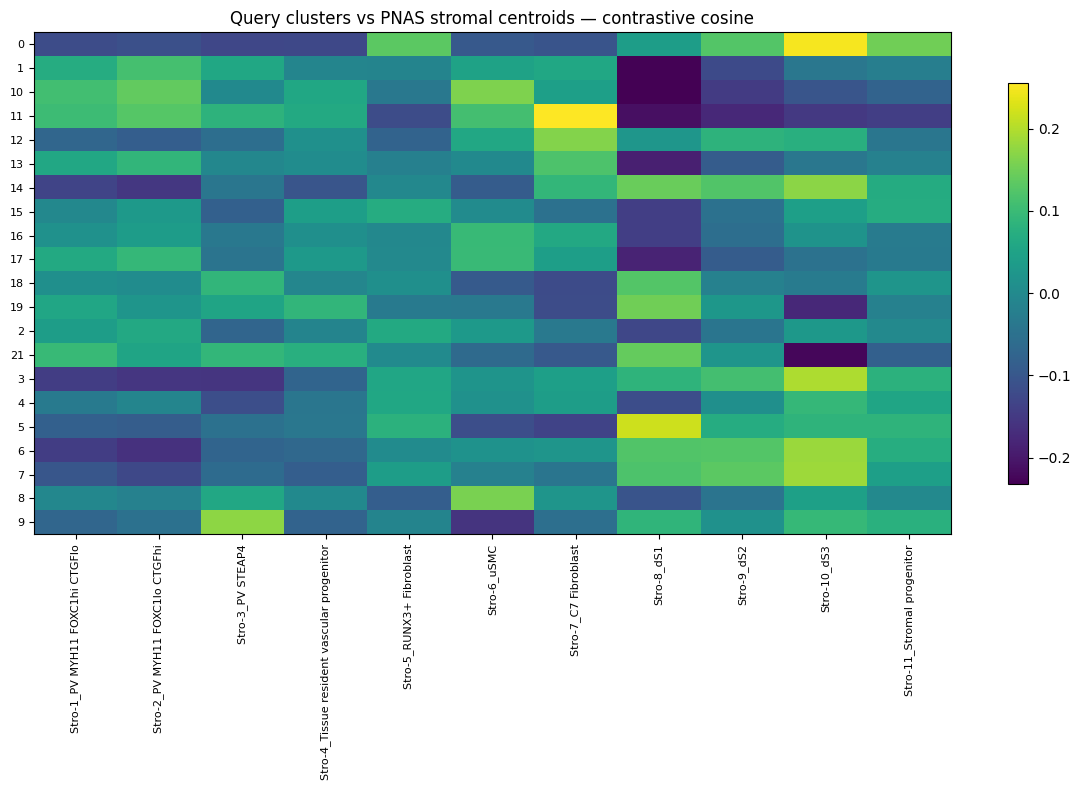

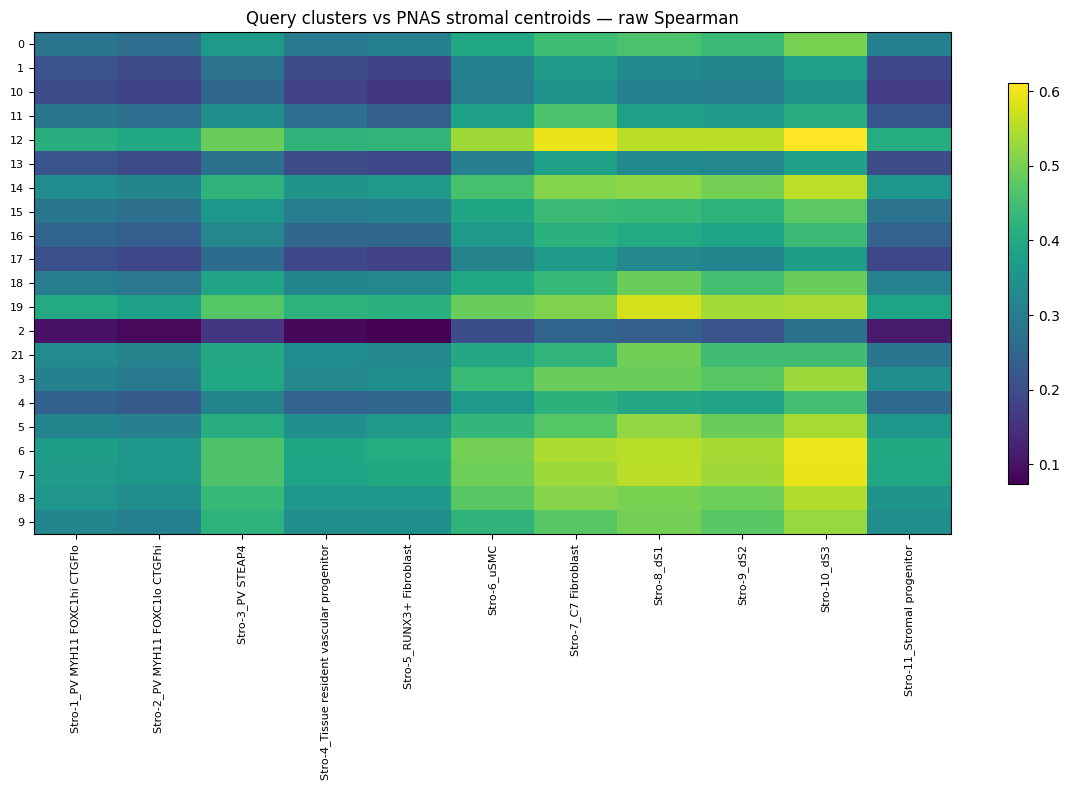

In [7]:
Q, cluster_n = pseudobulk_centroids(
    human, CLUSTER_KEY, panel, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
)
A = df.loc[panel, stro]

M_cos = contrastive_cosine(Q, A)
M_spr = raw_spearman(Q, A)

print("Contrastive cosine reciprocal mapping:")
recip_cos = reciprocal_table(M_cos)
display(recip_cos.sort_values(["mutual_nn", "margin"], ascending=False).round(3))

print("\nRaw Spearman reciprocal mapping:")
recip_spr = reciprocal_table(M_spr)
display(recip_spr.sort_values(["mutual_nn", "margin"], ascending=False).round(3))

plot_similarity_heatmap(M_cos, "Query clusters vs PNAS stromal centroids — contrastive cosine")
plot_similarity_heatmap(M_spr, "Query clusters vs PNAS stromal centroids — raw Spearman")

## 7. Which query cluster is the atlas Stro-7 centroid's best match?

In [8]:
stro7_query_cos = M_cos[STRO7].sort_values(ascending=False)
stro7_query_spr = M_spr[STRO7].sort_values(ascending=False)

print("Contrastive cosine:")
display(stro7_query_cos.to_frame("Stro-7 similarity").head(10).round(3))

print("\nRaw Spearman:")
display(stro7_query_spr.to_frame("Stro-7 correlation").head(10).round(3))

CANDIDATE_CLUSTER = stro7_query_cos.index[0]
print("\nDefault candidate cluster from Stro-7 reciprocal projection:", CANDIDATE_CLUSTER)

Contrastive cosine:


,Stro-7 similarity
11,0.256
12,0.165
13,0.120
14,0.090
16,0.062
1,0.058
10,0.044
3,0.044
17,0.042
4,0.040



Raw Spearman:


,Stro-7 correlation
12,0.595
6,0.545
7,0.532
8,0.513
14,0.511
19,0.508
3,0.489
9,0.473
5,0.470
11,0.459



Default candidate cluster from Stro-7 reciprocal projection: 11


# Part II — Explicit C7 discriminant axes

## 8. Build Stro-7-vs-competitor contrasts

Rather than asking only about overall centroid resemblance, construct explicit reference axes for what makes Stro-7 different from its competitors.

Positive weights = genes high in Stro-7 relative to the competitor set.  
Negative weights = genes favoring competitors.

In [9]:
def find_cols(tokens):
    return [c for c in stro if any(t.lower() in c.lower() for t in tokens)]

competitor_sets = {
    "vs_all_stroma": [c for c in stro if c != STRO7],
    "vs_decidual": find_cols(["dS1", "dS2", "dS3", "decidual"]),
    "vs_progenitor": find_cols(["Stromal progenitor"]),
    "vs_RUNX3_fibroblast": find_cols(["RUNX3"]),
    "vs_PV_uSMC": find_cols(["PV", "uSMC", "smooth muscle"]),
}

# Remove empty sets but print them for inspection.
for k, v in competitor_sets.items():
    print(k, "->", v)

def discriminant_weights(atlas, target, competitors, mode="mean"):
    assert len(competitors) > 0
    if mode == "mean":
        bg = atlas.loc[:, competitors].mean(axis=1)
    elif mode == "max":
        bg = atlas.loc[:, competitors].max(axis=1)
    else:
        raise ValueError(mode)
    return atlas[target] - bg

disc = pd.DataFrame({
    name: discriminant_weights(A, STRO7, comps, mode="mean")
    for name, comps in competitor_sets.items()
    if len(comps) > 0
})

display(disc.sort_values("vs_all_stroma", ascending=False).head(30).round(3))

vs_all_stroma -> ['Stro-1_PV MYH11 FOXC1hi CTGFlo', 'Stro-2_PV MYH11 FOXC1lo CTGFhi', 'Stro-3_PV STEAP4', 'Stro-4_Tissue resident vascular progenitor', 'Stro-5_RUNX3+ Fibroblast', 'Stro-6_uSMC', 'Stro-8_dS1', 'Stro-9_dS2', 'Stro-10_dS3', 'Stro-11_Stromal progenitor']
vs_decidual -> ['Stro-8_dS1', 'Stro-9_dS2', 'Stro-10_dS3']
vs_progenitor -> ['Stro-11_Stromal progenitor']
vs_RUNX3_fibroblast -> ['Stro-5_RUNX3+ Fibroblast']
vs_PV_uSMC -> ['Stro-1_PV MYH11 FOXC1hi CTGFlo', 'Stro-2_PV MYH11 FOXC1lo CTGFhi', 'Stro-3_PV STEAP4', 'Stro-6_uSMC']


,vs_all_stroma,vs_decidual,vs_progenitor,vs_RUNX3_fibroblast,vs_PV_uSMC
APOD,2.503,1.617,2.560,2.808,3.130
DCN,2.359,1.471,2.385,2.396,3.015
C7,2.127,2.060,2.226,2.206,2.195
CCDC80,2.026,1.945,2.249,2.157,2.044
SERPINF1,1.883,1.247,1.881,2.006,2.324
MGP,1.875,2.210,2.324,2.245,1.453
ADH1B,1.844,1.841,1.942,1.935,1.835
GSN,1.678,1.946,2.083,2.018,1.454
OGN,1.663,1.437,1.896,1.585,1.795
LUM,1.572,0.573,0.872,1.620,2.415


## 9. Project query-cluster centroids onto the C7 contrast axes

For interpretability, standardize each gene across query clusters and take a weighted mean using the reference discriminant vector.

This is not treated as a calibrated probability; it is a directional score.

In [10]:
Qz = Q.sub(Q.mean(axis=1), axis=0).div(Q.std(axis=1).replace(0, np.nan), axis=0)

disc_scores = {}
for name in disc.columns:
    w = disc[name].copy()
    keep = w.notna() & Qz.index.to_series().isin(Qz.index)
    w = w.loc[keep]
    Z = Qz.loc[w.index]
    denom = np.abs(w).sum()
    disc_scores[name] = (Z.mul(w, axis=0).sum(axis=0) / denom)

disc_scores = pd.DataFrame(disc_scores)
display(disc_scores.sort_values("vs_all_stroma", ascending=False).round(3))

,vs_all_stroma,vs_decidual,vs_progenitor,vs_RUNX3_fibroblast,vs_PV_uSMC
11,0.433,0.660,0.465,0.345,0.183
12,0.290,0.271,0.165,0.281,0.242
13,0.212,0.270,0.141,0.120,0.141
17,0.118,0.146,0.136,0.097,0.055
1,0.118,0.188,0.145,0.093,0.027
4,0.104,0.050,0.012,0.037,0.126
10,0.100,0.199,0.176,0.090,-0.010
16,0.094,0.092,0.126,0.097,0.048
2,0.056,-0.012,0.137,0.030,0.043
3,0.052,-0.036,-0.034,0.019,0.102


# Part III — Marker ablation robustness

## 10. Remove C7 / CFH / CTSK and rerun the reciprocal map

If the same query population still maps to Stro-7 after removing the headline markers, the result is much harder to explain as a trivial marker-driven assignment.

In [11]:
HEADLINE = [g for g in ["C7", "CFH", "CTSK"] if g in panel]
panel_no_headline = panel.difference(HEADLINE)

Q0, _ = pseudobulk_centroids(
    human, CLUSTER_KEY, panel_no_headline, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
)
A0 = df.loc[panel_no_headline, stro]
M0 = contrastive_cosine(Q0, A0)

print("Removed:", HEADLINE)
display(reciprocal_table(M0).sort_values(["mutual_nn", "margin"], ascending=False).round(3))
print("\nStro-7 -> query:")
display(M0[STRO7].sort_values(ascending=False).to_frame("similarity").head(10).round(3))

Removed: ['C7', 'CFH', 'CTSK']


,best_atlas,query_to_atlas_score,margin,atlas_best_query,mutual_nn
query,,,,,
5,Stro-8_dS1,0.218,0.132,5,True
11,Stro-7_C7 Fibroblast,0.257,0.129,11,True
0,Stro-10_dS3,0.249,0.100,0,True
9,Stro-3_PV STEAP4,0.174,0.078,9,True
10,Stro-6_uSMC,0.162,0.023,10,True
8,Stro-6_uSMC,0.158,0.098,10,False
3,Stro-10_dS3,0.195,0.086,0,False
12,Stro-7_C7 Fibroblast,0.167,0.084,11,False
19,Stro-8_dS1,0.149,0.060,5,False



Stro-7 -> query:


,similarity
11,0.257
12,0.167
13,0.123
14,0.093
16,0.065
1,0.060
10,0.046
17,0.044
4,0.041
3,0.040


## 11. Progressively remove the top Stro-7-specific genes

We rank genes by:

`Stro-7 - max(other stromal centroid)`

Then progressively remove the top 3, 5, 10, 20, 50, 100 genes and recompute:

- Stro-7's best query cluster
- the candidate cluster's best atlas subtype
- reciprocal status
- the candidate's Stro-7 margin.

,top_genes_removed,stro7_best_query,candidate_best_atlas,mutual_candidate_stro7,candidate_stro7_score,candidate_margin
0,0,11,Stro-7_C7 Fibroblast,True,0.256,0.129
1,3,11,Stro-7_C7 Fibroblast,True,0.252,0.123
2,5,11,Stro-7_C7 Fibroblast,True,0.252,0.119
3,10,11,Stro-7_C7 Fibroblast,True,0.259,0.125
4,20,11,Stro-7_C7 Fibroblast,True,0.263,0.127
5,50,11,Stro-7_C7 Fibroblast,True,0.233,0.081
6,100,11,Stro-7_C7 Fibroblast,True,0.219,0.054


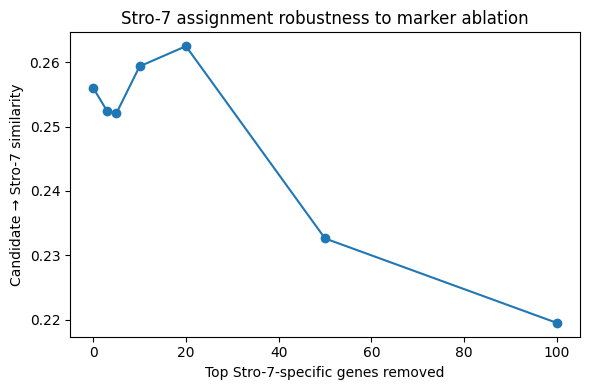

In [12]:
stro7_specificity = (
    A[STRO7] - A.drop(columns=STRO7).max(axis=1)
).sort_values(ascending=False)

remove_grid = [0, 3, 5, 10, 20, 50, 100]
ablation_rows = []

for k in remove_grid:
    remove = set(stro7_specificity.head(k).index)
    genes = pd.Index([g for g in panel if g not in remove])
    if len(genes) < 20:
        continue

    Qk, _ = pseudobulk_centroids(
        human, CLUSTER_KEY, genes, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
    )
    Ak = df.loc[genes, stro]
    Mk = contrastive_cosine(Qk, Ak)

    q_best = Mk.idxmax(axis=1)
    a_best = Mk.idxmax(axis=0)

    candidate = CANDIDATE_CLUSTER
    vals = Mk.loc[candidate].sort_values(ascending=False)
    margin = vals.iloc[0] - vals.iloc[1]

    ablation_rows.append({
        "top_genes_removed": k,
        "stro7_best_query": a_best[STRO7],
        "candidate_best_atlas": q_best[candidate],
        "mutual_candidate_stro7": (
            q_best[candidate] == STRO7 and a_best[STRO7] == candidate
        ),
        "candidate_stro7_score": Mk.loc[candidate, STRO7],
        "candidate_margin": margin,
    })

ablation = pd.DataFrame(ablation_rows)
display(ablation.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ablation["top_genes_removed"], ablation["candidate_stro7_score"], marker="o")
ax.set_xlabel("Top Stro-7-specific genes removed")
ax.set_ylabel("Candidate → Stro-7 similarity")
ax.set_title("Stro-7 assignment robustness to marker ablation")
fig.tight_layout()

# Part IV — Gene bootstrap and held-out-gene validation

## 12. Bootstrap the reference mapping over genes

This estimates whether the same assignment is supported broadly across the transcriptome rather than by a small collection of genes.

For each bootstrap:
- sample a fraction of genes without replacement,
- recompute the contrastive similarity matrix,
- record query→atlas and atlas→query assignments.

In [13]:
boot_rows = []

base_genes = pd.Index(panel)

for b in range(N_BOOT):
    n = max(50, int(len(base_genes) * BOOT_FRAC))
    genes = pd.Index(RNG.choice(base_genes.to_numpy(), size=n, replace=False))

    Qb, _ = pseudobulk_centroids(
        human, CLUSTER_KEY, genes, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
    )
    Ab = df.loc[genes, stro]
    Mb = contrastive_cosine(Qb, Ab)

    q_best = Mb.idxmax(axis=1)
    a_best = Mb.idxmax(axis=0)

    for q in Mb.index:
        boot_rows.append({
            "boot": b,
            "query": q,
            "best_atlas": q_best[q],
            "stro7_is_best": q_best[q] == STRO7,
            "stro7_best_query": a_best[STRO7],
            "mutual_stro7": (q_best[q] == STRO7 and a_best[STRO7] == q),
            "stro7_score": Mb.loc[q, STRO7],
        })

boot = pd.DataFrame(boot_rows)

boot_summary = (
    boot.groupby("query")
    .agg(
        p_query_maps_to_stro7=("stro7_is_best", "mean"),
        p_stro7_maps_to_query=("stro7_best_query", lambda x: np.mean(x == x.name) if False else np.nan),
        p_mutual_stro7=("mutual_stro7", "mean"),
        mean_stro7_score=("stro7_score", "mean"),
        sd_stro7_score=("stro7_score", "std"),
    )
)

# The atlas->query probability needs an explicit calculation.
p_a_to_q = (
    boot[["boot", "stro7_best_query"]]
    .drop_duplicates()
    ["stro7_best_query"]
    .value_counts(normalize=True)
)
boot_summary["p_stro7_maps_to_query"] = p_a_to_q.reindex(boot_summary.index).fillna(0)

display(
    boot_summary.sort_values(
        ["p_mutual_stro7", "p_query_maps_to_stro7"], ascending=False
    ).round(3)
)

,p_query_maps_to_stro7,p_stro7_maps_to_query,p_mutual_stro7,mean_stro7_score,sd_stro7_score
query,,,,,
11,1.000,1.0,1.0,0.255,0.016
12,1.000,0.0,0.0,0.165,0.014
13,0.852,0.0,0.0,0.120,0.019
16,0.034,0.0,0.0,0.061,0.016
1,0.022,0.0,0.0,0.058,0.015
4,0.020,0.0,0.0,0.040,0.015
17,0.004,0.0,0.0,0.041,0.017
8,0.002,0.0,0.0,0.022,0.021
0,0.000,0.0,0.0,-0.105,0.014


## 13. Discovery / validation gene splits

For each repetition:

1. randomly split informative genes into discovery and validation sets;
2. use **discovery genes only** to identify which query cluster is the best Stro-7 match;
3. freeze that candidate;
4. measure on **held-out validation genes** whether that query cluster still resembles Stro-7 and whether the reciprocal mapping persists.

This is stronger than selecting and validating on the same genes.

In [14]:
split_rows = []
informative = stro7_specificity.head(min(TOP_STRO7_MARKERS, len(stro7_specificity))).index

for b in range(N_BOOT):
    perm = RNG.permutation(informative.to_numpy())
    cut = max(20, int(len(perm) * DISCOVERY_FRAC))
    discovery = pd.Index(perm[:cut])
    validation = pd.Index(perm[cut:])

    if len(validation) < 20:
        continue

    # Discovery selection
    Qd, _ = pseudobulk_centroids(
        human, CLUSTER_KEY, discovery, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
    )
    Ad = df.loc[discovery, stro]
    Md = contrastive_cosine(Qd, Ad)
    selected_query = Md[STRO7].idxmax()

    # Held-out validation
    Qv, _ = pseudobulk_centroids(
        human, CLUSTER_KEY, validation, layer=LOG_LAYER, min_n=MIN_CLUSTER_N
    )
    Av = df.loc[validation, stro]
    Mv = contrastive_cosine(Qv, Av)

    q_best = Mv.idxmax(axis=1)
    a_best = Mv.idxmax(axis=0)

    vals = Mv.loc[selected_query].sort_values(ascending=False)
    margin = vals.iloc[0] - vals.iloc[1]

    split_rows.append({
        "split": b,
        "selected_query_discovery": selected_query,
        "validation_best_atlas": q_best[selected_query],
        "validation_stro7_best_query": a_best[STRO7],
        "validation_mutual_stro7": (
            q_best[selected_query] == STRO7 and a_best[STRO7] == selected_query
        ),
        "validation_stro7_score": Mv.loc[selected_query, STRO7],
        "validation_margin": margin,
    })

split_res = pd.DataFrame(split_rows)

print("Discovery-selected query frequencies:")
display(
    split_res["selected_query_discovery"]
    .value_counts(normalize=True)
    .to_frame("fraction")
    .round(3)
)

print("\nHeld-out validation mutual Stro-7 rate:")
print(round(split_res["validation_mutual_stro7"].mean(), 3))

display(split_res.head())

Discovery-selected query frequencies:


,fraction
selected_query_discovery,
11,0.688
14,0.208
8,0.048
12,0.036
3,0.016
6,0.004



Held-out validation mutual Stro-7 rate:
0.402


,split,selected_query_discovery,validation_best_atlas,validation_stro7_best_query,validation_mutual_stro7,validation_stro7_score,validation_margin
0,0,11,Stro-7_C7 Fibroblast,11,True,0.388959,0.344674
1,1,11,Stro-7_C7 Fibroblast,11,True,0.360402,0.385413
2,2,11,Stro-7_C7 Fibroblast,12,False,0.373837,0.356210
3,3,11,Stro-7_C7 Fibroblast,11,True,0.442838,0.294323
4,4,14,Stro-7_C7 Fibroblast,11,False,0.238670,0.016541


# Part V — Donor replication

## 14. Donor × cluster pseudobulk mapping

A pooled cluster can look convincing because one donor dominates it.  
Here, each donor × query-cluster combination becomes an independent pseudobulk centroid.

The useful pattern is:

- the same query cluster is Stro-7-like in multiple donors,
- the assignment is not restricted to one sample,
- and donor-specific profiles do not flip systematically to other stromal classes.

In [15]:
DQC, dqc_meta = donor_cluster_centroids(
    human, DONOR_KEY, CLUSTER_KEY, panel, layer=LOG_LAYER, min_n=10
)

Mdq = contrastive_cosine(DQC, A)
dq_best = Mdq.idxmax(axis=1)

dqc_result = dqc_meta.copy()
dqc_result["best_atlas"] = dq_best
dqc_result["stro7_score"] = Mdq[STRO7]
dqc_result["is_stro7_best"] = dqc_result["best_atlas"] == STRO7

display(
    dqc_result.sort_values(
        ["cluster", "donor", "stro7_score"], ascending=[True, True, False]
    ).round(3)
)

candidate_donor = dqc_result[dqc_result["cluster"] == str(CANDIDATE_CLUSTER)]
print("\nCandidate cluster across donors:")
display(candidate_donor.sort_values("stro7_score", ascending=False).round(3))

,donor,cluster,n,best_atlas,stro7_score,is_stro7_best
key,,,,,,
menstrual_mck5a|||0,menstrual_mck5a,0,335,Stro-10_dS3,-0.061,False
menstrual_mck5b|||0,menstrual_mck5b,0,314,Stro-10_dS3,-0.073,False
menstrual_mck5c|||0,menstrual_mck5c,0,286,Stro-10_dS3,-0.075,False
secretory_mck6a|||0,secretory_mck6a,0,501,Stro-10_dS3,-0.116,False
secretory_mck6b|||0,secretory_mck6b,0,482,Stro-10_dS3,-0.123,False
...,...,...,...,...,...,...
menstrual_mck5b|||9,menstrual_mck5b,9,283,Stro-3_PV STEAP4,-0.054,False
menstrual_mck5c|||9,menstrual_mck5c,9,259,Stro-3_PV STEAP4,-0.053,False
secretory_mck6a|||9,secretory_mck6a,9,36,Stro-3_PV STEAP4,-0.103,False



Candidate cluster across donors:


,donor,cluster,n,best_atlas,stro7_score,is_stro7_best
key,,,,,,
secretory_mck6c|||11,secretory_mck6c,11,601,Stro-7_C7 Fibroblast,0.274,True
secretory_mck6a|||11,secretory_mck6a,11,995,Stro-7_C7 Fibroblast,0.258,True
secretory_mck6b|||11,secretory_mck6b,11,992,Stro-7_C7 Fibroblast,0.239,True
menstrual_mck5a|||11,menstrual_mck5a,11,483,Stro-7_C7 Fibroblast,0.222,True
menstrual_mck5c|||11,menstrual_mck5c,11,491,Stro-7_C7 Fibroblast,0.215,True
menstrual_mck5b|||11,menstrual_mck5b,11,497,Stro-7_C7 Fibroblast,0.201,True


## 15. Donor-level similarity to the Stro-7-specific expression vector

For the candidate cluster, correlate each donor-specific pseudobulk with the published Stro-7 centroid using the top discriminative genes.

In [16]:
mk = stro7_specificity.head(min(TOP_STRO7_MARKERS, len(stro7_specificity))).index

donor_corr_rows = []
for key, row in dqc_meta.iterrows():
    if row["cluster"] != str(CANDIDATE_CLUSTER):
        continue
    rho = DQC.loc[mk, key].corr(df.loc[mk, STRO7], method="spearman")
    donor_corr_rows.append({
        "donor": row["donor"],
        "cluster": row["cluster"],
        "n": row["n"],
        "spearman_vs_stro7": rho,
    })

donor_corr = pd.DataFrame(donor_corr_rows).sort_values("spearman_vs_stro7", ascending=False)
display(donor_corr.round(3))

,donor,cluster,n,spearman_vs_stro7
5,secretory_mck6c,11,601,0.248
3,secretory_mck6a,11,995,0.215
4,secretory_mck6b,11,992,0.203
0,menstrual_mck5a,11,483,0.142
2,menstrual_mck5c,11,491,0.136
1,menstrual_mck5b,11,497,0.111


# Part VI — Does Stro-7 add unique explanatory information?

## 16. Held-out-gene archetype ablation

Fit each query cluster centroid as a nonnegative combination of reference stromal archetypes.

Compare:
- full reference basis (includes Stro-7)
- ablated basis (Stro-7 removed)

Evaluate on held-out genes.

If adding Stro-7 improves prediction specifically for the candidate cluster, Stro-7 is providing information not easily reconstructed from the other stromal centroids.

This is an exploratory prototype-basis test; coefficients should **not** be interpreted as literal cell fractions.

In [17]:
from scipy.optimize import nnls

def archetype_ablation_once(query, atlas, genes_train, genes_test, target_col):
    full_cols = list(atlas.columns)
    ablated_cols = [c for c in full_cols if c != target_col]

    rows = []
    for q in query.columns:
        y_train = query.loc[genes_train, q].to_numpy(float)
        y_test = query.loc[genes_test, q].to_numpy(float)

        Xf_train = atlas.loc[genes_train, full_cols].to_numpy(float)
        Xa_train = atlas.loc[genes_train, ablated_cols].to_numpy(float)

        bf, _ = nnls(Xf_train, y_train)
        ba, _ = nnls(Xa_train, y_train)

        pred_f = atlas.loc[genes_test, full_cols].to_numpy(float) @ bf
        pred_a = atlas.loc[genes_test, ablated_cols].to_numpy(float) @ ba

        mse_f = np.mean((y_test - pred_f) ** 2)
        mse_a = np.mean((y_test - pred_a) ** 2)

        rows.append({
            "query": q,
            "mse_full": mse_f,
            "mse_no_stro7": mse_a,
            "delta_mse_no_stro7_minus_full": mse_a - mse_f,
        })
    return pd.DataFrame(rows)

abl_rows = []
for b in range(min(N_BOOT, 200)):
    genes = RNG.permutation(panel.to_numpy())
    cut = len(genes) // 2
    tr = pd.Index(genes[:cut])
    te = pd.Index(genes[cut:])

    z = archetype_ablation_once(Q, A, tr, te, STRO7)
    z["split"] = b
    abl_rows.append(z)

archetype = pd.concat(abl_rows, ignore_index=True)

arch_summary = (
    archetype.groupby("query")["delta_mse_no_stro7_minus_full"]
    .agg(["mean", "median", "std", "count"])
    .sort_values("mean", ascending=False)
)
display(arch_summary.round(5))

,mean,median,std,count
query,,,,
11,0.00163,0.00174,0.00056,200
12,0.00032,0.00043,0.00036,200
13,0.00018,0.00029,0.00029,200
10,0.00009,0.00017,0.00021,200
18,0.00000,0.00000,0.00000,200
5,0.00000,0.00000,0.00000,200
21,0.00000,0.00000,0.00000,200
19,0.00000,0.00000,0.00000,200
9,-0.00000,0.00000,0.00000,200


# Part VII — Optional reverse classifier

## 17. Train a classifier on donor × query-cluster pseudobulks, then classify the published centroids

This implements the idea:

> “If I learn the geometry of *my* query clusters, where does the published Stro-7 centroid land?”

Important limitation: a classifier trained on individual sparse nuclei would have a strong domain mismatch with a dense centroid.  
Training on donor × cluster pseudobulks makes the input scale more comparable.

We first evaluate whether the classifier can recognize query clusters under **leave-one-donor-out** validation.  
Only then do we apply it to the PNAS centroids.

In [18]:
# Use genes present in the donor-cluster pseudobulk matrix and atlas.
clf_genes = panel

X = DQC.loc[clf_genes].T.to_numpy(float)
y = dqc_meta.loc[DQC.columns, "cluster"].to_numpy(str)
groups = dqc_meta.loc[DQC.columns, "donor"].to_numpy(str)

logo = LeaveOneGroupOut()
pred = np.empty(len(y), dtype=object)

for train, test in logo.split(X, y, groups):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X[train])
    Xte = scaler.transform(X[test])

    clf = LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        multi_class="auto",
        random_state=RANDOM_STATE,
    )
    clf.fit(Xtr, y[train])
    pred[test] = clf.predict(Xte)

print("Leave-one-donor-out balanced accuracy:",
      round(balanced_accuracy_score(y, pred), 3))
print(classification_report(y, pred, zero_division=0))

# Final fit on all donor×cluster pseudobulks.
scaler = StandardScaler()
Xall = scaler.fit_transform(X)

clf = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    multi_class="auto",
    random_state=RANDOM_STATE,
)
clf.fit(Xall, y)

atlas_X = df.loc[clf_genes, stro].T.to_numpy(float)
atlas_Xs = scaler.transform(atlas_X)

atlas_pred = pd.DataFrame(
    clf.predict_proba(atlas_Xs),
    index=stro,
    columns=clf.classes_,
)
atlas_pred["predicted_query_cluster"] = clf.predict(atlas_Xs)
atlas_pred["max_probability"] = atlas_pred[clf.classes_].max(axis=1)

display(
    atlas_pred.loc[:, ["predicted_query_cluster", "max_probability"]]
    .sort_values("max_probability", ascending=False)
    .round(3)
)

print("\nPNAS Stro-7 reverse-classifier prediction:")
display(atlas_pred.loc[[STRO7]].round(3))

TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

# Part VIII — Unsmoothed per-cell prototype scores

## 18. Per-cell Stro-7 contrast score without kNN expression smoothing

The previous notebook averaged expression over a 30-NN graph before comparing cells to reference centroids.  
That is useful for visualization but can borrow signal across donors and smear rare states.

Here we score **each nucleus directly** using a compact set of Stro-7-specific genes.

Because individual snRNA counts are sparse, interpret this primarily as a continuous ranking.  
Use donor-level metacells / pseudobulks for stronger identity claims.

In [ ]:
# Positive Stro-7 genes: high specificity versus every other stromal centroid.
stro7_pos = (
    A[STRO7] - A.drop(columns=STRO7).max(axis=1)
).sort_values(ascending=False)

POS_GENES = [
    g for g in stro7_pos.head(100).index
    if g in human.var_names
]

# A broad set of competitor-positive genes provides a negative program.
other_best = A.drop(columns=STRO7).max(axis=1) - A[STRO7]
NEG_GENES = [
    g for g in other_best.sort_values(ascending=False).head(100).index
    if g in human.var_names and g not in POS_GENES
]

print("Positive genes:", len(POS_GENES))
print(POS_GENES[:30])
print("\nNegative genes:", len(NEG_GENES))
print(NEG_GENES[:30])

# Explicitly use the desired log-normalized layer in temporary AnnData objects.
tmp = ad.AnnData(
    X=human.layers[LOG_LAYER],
    obs=human.obs[[]].copy(),
    var=human.var[[]].copy(),
)

sc.tl.score_genes(
    tmp, POS_GENES, score_name="c7_positive",
    use_raw=False, random_state=RANDOM_STATE
)
sc.tl.score_genes(
    tmp, NEG_GENES, score_name="c7_competitor",
    use_raw=False, random_state=RANDOM_STATE
)

human.obs["c7_positive"] = tmp.obs["c7_positive"].to_numpy()
human.obs["c7_competitor"] = tmp.obs["c7_competitor"].to_numpy()
human.obs["c7_contrast"] = (
    human.obs["c7_positive"] - human.obs["c7_competitor"]
)

## 19. UMAP: C7 contrast, candidate cluster, headline markers

In [ ]:
colors = ["c7_contrast", CLUSTER_KEY]
for g in ["C7", "CFH", "CTSK", "CXCL12", "RSPO1", "FGF7"]:
    if g in human.var_names:
        colors.append(g)

sc.pl.embedding(
    human,
    basis=UMAP_KEY,
    color=colors,
    layer=LOG_LAYER,
    cmap="viridis",
    ncols=3,
    frameon=False,
    size=8,
)

## 20. Donor-specific distribution of the C7 contrast score

The pooled UMAP can hide donor specificity.  
Inspect the same score within each donor.

In [ ]:
donors = sorted(human.obs[DONOR_KEY].astype(str).unique())

fig, axes = plt.subplots(
    1, len(donors),
    figsize=(3.5 * len(donors), 3.5),
    squeeze=False
)
axes = axes.ravel()

v = human.obs["c7_contrast"].to_numpy(float)
lim = np.nanpercentile(np.abs(v), 99)

for ax, d in zip(axes, donors):
    m = (human.obs[DONOR_KEY].astype(str) == d).to_numpy()
    xy = human.obsm[UMAP_KEY][m]
    vv = v[m]
    o = np.argsort(np.abs(vv))
    pts = ax.scatter(
        xy[o, 0], xy[o, 1], c=vv[o], s=4,
        cmap="RdBu_r", vmin=-lim, vmax=lim,
        linewidths=0, rasterized=True
    )
    ax.set_title(f"{d} (n={m.sum():,})")
    ax.set_axis_off()

fig.colorbar(pts, ax=axes.tolist(), shrink=0.7, label="C7 contrast")
fig.tight_layout()

# Part IX — Negative-control identities

## 21. Marker panel for obvious alternatives

This is especially useful if the query object is broadened to all mesenchymal nuclei.

A C7 candidate should not simply be:
- smooth muscle,
- perivascular,
- decidual,
- or macrophage/immune contamination.

In [ ]:
marker_dict = {
    "C7/Stro7": ["C7", "CFH", "CTSK"],
    "generic_fibro": ["DCN", "LUM", "COL1A1", "COL3A1", "PDGFRA", "DPT", "OGN"],
    "PV": ["RGS5", "MCAM", "NOTCH3", "PDGFRB", "CSPG4"],
    "uSMC": ["ACTA2", "TAGLN", "MYH11", "DES"],
    "decidual": ["FOXO1", "WNT4", "IGFBP1", "PRL", "HAND2"],
    "immune_mac": ["PTPRC", "LST1", "TYROBP", "FCER1G", "CTSS"],
}

marker_dict = {
    k: [g for g in genes if g in human.var_names]
    for k, genes in marker_dict.items()
}
marker_dict = {k: v for k, v in marker_dict.items() if v}

sc.pl.dotplot(
    human,
    marker_dict,
    groupby=CLUSTER_KEY,
    layer=LOG_LAYER,
    use_raw=False,
    standard_scale="var",
)

# Part X — Spatial readout

## 22. Plot the C7 contrast and candidate cluster in tissue, per timepoint

This reproduces the useful spatial part of the earlier notebook but keeps the score unsmoothed.

**Caution:** this does not by itself establish basalis identity.  
The stronger anatomical analysis is distance to the myometrial boundary / basal glands, not radial distance from the coordinate median.

In [ ]:
if all(k in human.obs for k in [TIMEPOINT_KEY, X_KEY, Y_KEY]):
    obs = human.obs.copy()
    tps = list(obs[TIMEPOINT_KEY].astype(str).unique())

    score = obs["c7_contrast"].to_numpy(float)
    lim = np.nanpercentile(np.abs(score), 99)

    fig, axes = plt.subplots(
        2, len(tps),
        figsize=(3.3 * len(tps), 6.6),
        squeeze=False,
    )

    for j, tp in enumerate(tps):
        m = (obs[TIMEPOINT_KEY].astype(str) == tp).to_numpy()
        x = obs[X_KEY].to_numpy(float)
        y = obs[Y_KEY].to_numpy(float)
        ok = m & np.isfinite(x) & np.isfinite(y)

        # Continuous C7 contrast
        ax = axes[0, j]
        vv = score[ok]
        o = np.argsort(np.abs(vv))
        ax.scatter(
            x[ok][o], y[ok][o], c=vv[o],
            s=3, cmap="RdBu_r", vmin=-lim, vmax=lim,
            linewidths=0, rasterized=True
        )
        ax.set_title(tp)

        # Candidate cluster
        ax = axes[1, j]
        ax.scatter(x[ok], y[ok], c="0.9", s=2, linewidths=0, rasterized=True)
        cand = ok & (obs[CLUSTER_KEY].astype(str).to_numpy() == str(CANDIDATE_CLUSTER))
        ax.scatter(x[cand], y[cand], c="crimson", s=5, linewidths=0, rasterized=True)
        ax.set_title(f"{tp}: candidate n={cand.sum():,}")

    for ax in axes.ravel():
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.set_axis_off()

    axes[0, 0].set_ylabel("C7 contrast")
    axes[1, 0].set_ylabel("candidate cluster")
    fig.tight_layout()
else:
    print("Spatial metadata not available; skipped.")

## 23. Niche genes in candidate versus other clusters

HECA proposes C7+ basalis fibroblasts as a candidate niche population associated with **CXCL12**, with additional RSPO/WNT and FGF signaling.

These genes are supporting evidence, not defining markers, and can be sparse in nuclei.

In [ ]:
niche = [g for g in ["CXCL12", "RSPO1", "FGF7", "WNT5A", "C7", "CFH", "CTSK"] if g in human.var_names]

if niche:
    sc.pl.dotplot(
        human,
        niche,
        groupby=CLUSTER_KEY,
        layer=LOG_LAYER,
        use_raw=False,
        standard_scale="var",
    )

    expr_pos = {}
    for g in niche:
        x = human[:, g].layers[LOG_LAYER]
        if sp.issparse(x):
            v = np.asarray((x > 0).toarray()).ravel()
        else:
            v = np.asarray(x > 0).ravel()

        expr_pos[g] = (
            pd.Series(v, index=human.obs_names)
            .groupby(human.obs[CLUSTER_KEY].astype(str))
            .mean()
        )

    frac_pos = pd.DataFrame(expr_pos)
    display(frac_pos.round(3))

# Part XI — Export summary tables

The notebook writes compact CSVs so the result can be audited without re-running the plotting cells.

In [ ]:
OUTDIR = Path("c7_centroid_results")
OUTDIR.mkdir(exist_ok=True)

M_cos.to_csv(OUTDIR / "query_cluster_vs_pnas_stromal_contrastive_cosine.csv")
M_spr.to_csv(OUTDIR / "query_cluster_vs_pnas_stromal_spearman.csv")
recip_cos.to_csv(OUTDIR / "reciprocal_mapping_contrastive_cosine.csv")
recip_spr.to_csv(OUTDIR / "reciprocal_mapping_spearman.csv")
disc_scores.to_csv(OUTDIR / "c7_discriminant_scores_by_query_cluster.csv")
ablation.to_csv(OUTDIR / "stro7_marker_ablation.csv", index=False)
boot_summary.to_csv(OUTDIR / "gene_bootstrap_summary.csv")
split_res.to_csv(OUTDIR / "heldout_gene_split_results.csv", index=False)
dqc_result.to_csv(OUTDIR / "donor_cluster_mapping.csv")
donor_corr.to_csv(OUTDIR / "candidate_donor_stro7_correlations.csv", index=False)
arch_summary.to_csv(OUTDIR / "stro7_archetype_ablation_summary.csv")

# Per-cell fields useful for downstream plotting.
per_cell_cols = [
    DONOR_KEY, CLUSTER_KEY, "c7_positive", "c7_competitor", "c7_contrast"
]
for c in [TIMEPOINT_KEY, X_KEY, Y_KEY]:
    if c in human.obs and c not in per_cell_cols:
        per_cell_cols.append(c)

human.obs[per_cell_cols].to_csv(OUTDIR / "per_cell_c7_scores.csv")

print("Wrote results to:", OUTDIR.resolve())

# Part XII — Interpretation checklist

A convincing centroid-only result would look something like:

- **Reciprocal match:** the same query cluster maps to Stro-7 and Stro-7 maps back to it.
- **Not a sink:** other PNAS stromal centroids map to sensible distinct query clusters.
- **Headline-marker ablation:** the result survives removal of C7 / CFH / CTSK.
- **Progressive ablation:** it survives removal of many top Stro-7-specific genes.
- **Gene bootstrap:** the assignment recurs in most random gene subsets.
- **Held-out genes:** a cluster selected on discovery genes still validates on unseen genes.
- **Donor replication:** the same state is recovered independently in multiple donors.
- **Archetype ablation:** Stro-7 improves held-out prediction for the candidate more than for other query clusters.
- **Reverse classifier:** a classifier trained on donor×cluster pseudobulks sends the PNAS Stro-7 centroid to the same query cluster.
- **Negative controls:** the candidate is not simply PV, uSMC, decidual, or immune.
- **Spatial support:** candidate nuclei occupy the expected basal / endometrium–myometrium neighborhood.

If several of these fail, describe the result more cautiously as a **C7-like program** rather than a discrete C7 fibroblast population.

## Next strongest step if needed

If the centroid-only evidence is promising but ambiguous, move to cell/nucleus-level reference validation:
- HECA snRNA labels,
- Garcia-Alonso full-thickness snRNA,
- held-out-donor classifier / reference mapping.

That is a stronger independent validation than another forced joint integration.